In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

Palette = ['#ebc334', '#bd1041', '#76d5de', '#6250d6', '#48e348']
Tier_Order = ['hot desk', 'flex', 'dedicated desk', 'full time', 'private office']
Tier_Color = dict(zip(Tier_Order, Palette))
Graph_Color = ['#EA9F09', '#87cefa']
Edgecolor = ['#000000', '#FFFFFF']
Heatmap = ['PiYG', 'Blues']

# Information (raw data)

In [6]:
acdc_dataset = pd.read_csv('../Dataset/acdc_dataset.csv', sep=';')

# Data Description

In [7]:
acdc_dataset.head().T

,0,1,2,3,4
member_id,CW000001,CW000002,CW000003,CW000004,CW000005
age,38.0,38.0,43.0,38.0,45.0
gender,Female,Male,Male,F,Female
industry,Information Technology,Information Technology,Education,Legal,Information Technology
country,Portugal,Portugal,DE,portugal,United Kingdom
is_team_account,False,True,True,False,False
n_colleagues_on_account,0,2,1,0,0
plan_tier,flex,HOT_DESK,flex,flex,hot_desk
plan_days_per_week,3,2,3,3,2
membership_start,2021-08-01,2023-11-24,2021-12-03,2022-01-02,2023-10-24


In [8]:
acdc_dataset.tail().T

,15460,15461,15462,15463,15464
member_id,CW009828,CW005287,CW003868,CW013132,CW015101
age,29.0,19.0,28.0,32.0,46.0
gender,Female,Female,Female,Female,Male
industry,Unknown,Information Technology,Design & Creative,Legal,Information Technology
country,Spain,Germany,Portugal,Portugal,Portugal
is_team_account,False,False,True,False,False
n_colleagues_on_account,0,0,1,0,0
plan_tier,flex,private_office,hot_desk,dedicated_desk,flex
plan_days_per_week,3,7,2,5,3
membership_start,2022-12-09,2021-04-29,2023-12-27,2021-08-28,2022-02-04


In [9]:
acdc_dataset.shape

(15465, 31)

### Info() analysis

In [10]:
acdc_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

- 'lifetime_value', 'meeting_room_hours, 'plan_tier', 'country', 'gender' and 'age' have missing values.
- 'lifetime_value should be a numeric dtype but is an object.
- Date features are also stored as objects and must be converted to date or datetime.
- 'uses_print' should be boolean but is an int64.


### Describe() analysis

In [11]:
acdc_dataset.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


- age seems to have a few impossible values with a 149 years max and 1 year min.
- n_colleagues_on_account, days_since_last_visit, total_visits, meeting_room_hours, event_space_hours, guest_passes_issued and n_renewals all have negative values which are not possible.
- plan_days_per_week has impossible min of 0 and mas of 9, as we cannot have 0 days of usage per week neither can we have 9 days since a week only has 7.
- avg_weekly_visits has a unusual max value of 47.40, which would mean that a user is using the service more than 6 times a day.
- meeting_room_hours also has an strange and unusually high max value of 41220 hours, which is almost 5 years of usage, and we only have 3 years of data.
- uses_print is using 0 and 1 instead of a boolean and should be corrected.

In [12]:
acdc_dataset.describe(include=['object', 'bool']).T

C:\Users\tiago\AppData\Local\Temp\ipykernel_2264\1625073321.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  acdc_dataset.describe(include=['object', 'bool']).T


,count,unique,top,freq
member_id,15465,15450,CW015101,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
is_team_account,15465,2,False,11112
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
uses_meeting_rooms,15465,2,False,10202


- membership_end seems to have a placeholder value os 1970-01-01, which should be for users we active memberships. This is a common practice when there is no end date.
- gender is either very modern or has 10 incorrect recordings.

In [13]:
for col in ['gender', 'plan_tier', 'country', 'industry']:
    print(f'{col} ({acdc_dataset[col].nunique()} unique values)')
    print((acdc_dataset[col].value_counts(dropna=False, normalize=True) * 100).round(2).to_string())
    print()

gender (12 unique values)
gender
Female     47.94
Male       39.91
NaN         3.43
Other       3.01
female      1.09
F           0.92
 Female     0.91
M           0.89
male        0.85
 Male       0.83
other       0.10
 Other      0.06
O           0.05

plan_tier (19 unique values)
plan_tier
flex              33.51
hot_desk          32.16
full_time         15.02
dedicated_desk     9.58
private_office     4.07
Flex               0.89
FLEX               0.86
NaN                0.68
HOT_DESK           0.53
Hot Desk           0.52
hotdesk            0.51
fulltime           0.41
FULL_TIME          0.32
Full Time          0.25
DEDICATED_DESK     0.17
Dedicated Desk     0.16
dedicateddesk      0.12
Private Office     0.08
privateoffice      0.08
PRIVATE_OFFICE     0.06

country (33 unique values)
country
Portugal           64.40
United Kingdom      7.15
Germany             5.51
Spain               4.60
France              3.27
Netherlands         3.00
NaN                 2.78
Other (Europe) 

- the categorical variables have inconsistent labels for the same category, these must be adressed.

# Duplicates

In [14]:
print('Duplicated member_id:', acdc_dataset['member_id'].duplicated().sum())
print('Fully duplicated rows:',acdc_dataset.duplicated().sum())
print('Duplicated rows ignoring member_id:', acdc_dataset.drop(columns='member_id').duplicated().sum())

Duplicated member_id: 15
Fully duplicated rows: 15
Duplicated rows ignoring member_id: 182


- these results seem to show that there are users that are registred several times , 15 users that are fully duplicated and 15 users who have the same member id.

In [15]:
dup_ids = acdc_dataset[acdc_dataset['member_id'].duplicated(keep=False)].sort_values('member_id')
dup_ids.head(10).T

,959,15453,15454,1428,15462,3985,15461,5441,6011,15456
member_id,CW000935,CW000935,CW001390,CW001390,CW003868,CW003868,CW005287,CW005287,CW005845,CW005845
age,22.0,22.0,44.0,44.0,28.0,28.0,19.0,19.0,35.0,35.0
gender,Female,Female,Male,Male,Female,Female,Female,Female,Female,Female
industry,Unknown,Unknown,UNKNOWN,UNKNOWN,Design & Creative,Design & Creative,Information Technology,Information Technology,FINANCE,FINANCE
country,Portugal,Portugal,Portugal,Portugal,Portugal,Portugal,Germany,Germany,Portugal,Portugal
is_team_account,False,False,False,False,True,True,False,False,True,True
n_colleagues_on_account,0,0,0,0,1,1,0,0,3,3
plan_tier,FLEX,FLEX,hot_desk,hot_desk,hot_desk,hot_desk,private_office,private_office,dedicated_desk,dedicated_desk
plan_days_per_week,3,3,2,2,2,2,7,7,5,5
membership_start,2022-12-18,2022-12-18,28/10/2022,28/10/2022,2023-12-27,2023-12-27,2021-04-29,2021-04-29,2021-10-05,2021-10-05


- many duplicated users with different ids.

In [16]:
same_profile = acdc_dataset[acdc_dataset.drop(columns='member_id').duplicated(keep=False)]
same_profile.sort_values(['membership_start', 'age', 'total_visits']).head(10)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
9791,CW009520,36.0,Male,Real Estate,Portugal,False,0,hot_desk,2,07/09/2023,16/10/2023,07/09/2023,39,2,0.40,11.19,2,0.0,0.0,0.0,False,False,False,0,True,False,True,False,False,0,212.26
15228,CW015276,36.0,Male,Real Estate,Portugal,False,0,hot_desk,2,07/09/2023,16/10/2023,07/09/2023,39,2,0.40,11.19,2,0.0,0.0,0.0,False,False,False,0,True,False,True,False,False,0,212.26
545,CW000530,26.0,Female,Legal,Portugal,True,1,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-28,4,585,3.74,43.48,38,194.7,0.0,0.0,True,False,False,1,False,False,False,True,False,4,16114.96
12352,CW015227,26.0,Female,Legal,Portugal,True,1,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-28,4,585,3.74,43.48,38,194.7,0.0,0.0,True,False,False,1,False,False,False,True,False,4,16114.96
3380,CW003279,28.0,Male,Marketing & PR,Portugal,False,0,flex,3,2021-01-01,1970-01-01,2023-12-20,12,464,2.97,26.09,26,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,6475.56
15116,CW015289,28.0,Male,Marketing & PR,Portugal,False,0,flex,3,2021-01-01,1970-01-01,2023-12-20,12,464,2.97,26.09,26,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,6475.56
1283,CW015110,30.0,Male,Finance,Germany,False,0,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-30,2,564,3.60,43.48,32,171.5,0.0,57.0,True,False,True,1,True,True,True,True,False,3,18670.21
9933,CW009657,30.0,Male,Finance,Germany,False,0,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-30,2,564,3.60,43.48,32,171.5,0.0,57.0,True,False,True,1,True,True,True,True,False,3,18670.21
6437,CW006262,31.0,Female,Education,Germany,False,0,NaN,7,2021-01-01,1970-01-01,2023-12-20,999,168,1.07,60.87,11,66.6,0.0,19.0,True,False,True,0,True,True,False,True,False,2,0
13967,CW015140,31.0,Female,Education,Germany,False,0,NaN,7,2021-01-01,1970-01-01,2023-12-20,999,168,1.07,60.87,11,66.6,0.0,19.0,True,False,True,0,True,True,False,True,False,2,0


- this shows that there are several user registred twice with different ids.

In [17]:
# Fully duplicated rows, then members registered twice under different ids
acdc_dataset = acdc_dataset.drop_duplicates()
acdc_dataset = acdc_dataset[~acdc_dataset.drop(columns='member_id').duplicated(keep='first')].reset_index(drop=True)

print('Duplicated member_id:', acdc_dataset['member_id'].duplicated().sum())
acdc_dataset.shape

Duplicated member_id: 0


(15283, 31)

In [18]:
df_no_duplicates = acdc_dataset.drop_duplicates()                                   
df_no_duplicates = df_no_duplicates[~df_no_duplicates.drop(columns='member_id').duplicated(keep='first')]
df_no_duplicates = df_no_duplicates.set_index('member_id')

print('Duplicated index:', df_no_duplicates.index.duplicated().sum())
df_no_duplicates.shape

Duplicated index: 0


(15283, 30)

- we dropped all fully duplicated rows, as well as users who were registered more than once with different ids, keeping the first record of each.

# Missing Values

In [19]:
null_values = acdc_dataset.isnull().sum()
null_values = null_values[null_values > 0].sort_values(ascending=False)
null_values

meeting_room_hours     1281
guest_passes_issued    1256
lifetime_value         1028
age                     549
gender                  524
country                 424
plan_tier               103
dtype: int64

# Cleaning

### Gender

In [20]:
acdc_dataset['gender'].unique()

<StringArray>
['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male', ' Male', 'other', ' Other', 'female', 'O']
Length: 13, dtype: str

In [21]:
gender_dict = {
    'F': 'female',
    'M': 'male',                #fixing gender labels
    'O': 'Other'
               }

acdc_dataset['gender'] = acdc_dataset['gender'].replace(gender_dict)

acdc_dataset['gender'] = acdc_dataset['gender'].str.lower()

acdc_dataset['gender'] = acdc_dataset['gender'].str.strip()

acdc_dataset['gender'].unique()

<StringArray>
['female', 'male', 'other', nan]
Length: 4, dtype: str

### Industry

In [22]:
acdc_dataset['industry'].unique()

<StringArray>
['Information Technology',              'Education',                  'Legal',                 'Health',                'Unknown',                  'Other',             'Consulting',
      'Design & Creative', 'information technology',                'Finance',         'Marketing & PR',              'EDUCATION',      'DESIGN & CREATIVE',       'Marketing and PR',
            'Real Estate',                  'other',             'consulting',         'MARKETING & PR', 'Information technology',      'design & creative',                  'LEGAL',
         'marketing & pr', 'INFORMATION TECHNOLOGY',                 'health',           'Marketing/PR',             'CONSULTING',                'unknown',        'Design/Creative',
             'RealEstate',                     'IT',                   'Tech',         'Marketing & Pr',                  'OTHER',                  'legal',                'finance',
            'real estate',              'education',    'Design and Cre

In [23]:
industry_dict = {
    'realestate': 'real estate',
    'it': 'information technology',
    'tech': 'information technology'
}

s = (
    acdc_dataset['industry']
    .astype('string')
    .str.strip()
    .str.lower()
    .str.replace('/', ' & ', regex=False)
    .str.replace(r'\band\b', '&', regex=True)
    .str.replace(r'[-_]', ' ', regex=True)
    .str.replace(r'\s*&\s*', ' & ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

acdc_dataset['industry'] = s.replace(industry_dict)
acdc_dataset['industry'].unique()


<StringArray>
['information technology', 'education', 'legal', 'health', 'unknown', 'other', 'consulting', 'design & creative', 'finance', 'marketing & pr', 'real estate']
Length: 11, dtype: string

### Country

In [24]:
acdc_dataset['country'].unique()

<StringArray>
[       'Portugal',              'DE',        'portugal',  'United Kingdom',           'Spain',         'Germany',     'Netherlands',          'France',              'PT',  'Other (Europe)',
        'Portucal',               nan,              'UK',         'Ireland',  'United kingdom',              'IE',       'portugal ',     'Deutschland',         'ireland',         'germany',
          'france',  'united kingdom',  'other (europe)',            'U.K.',              'GB',              'ES',              'NL',          'España',          'Espana',     'netherlands',
           'spain', 'The Netherlands',              'FR',         'Holland']
Length: 34, dtype: str

In [25]:
country_dict = {
    'portucal': 'portugal',
    'pt': 'portugal',
    'de': 'germany',
    'deutschland': 'germany',
    'uk': 'united kingdom',
    'u.k.': 'united kingdom',
    'gb': 'united kingdom',
    'ie': 'ireland',
    'es': 'spain',
    'españa': 'spain',
    'espana': 'spain',
    'fr': 'france',
    'nl': 'netherlands',
    'the netherlands': 'netherlands',
    'holland': 'netherlands'
}

# Standardize spelling/case first so that all variants can be mapped consistently.
acdc_dataset['country'] = (
    acdc_dataset['country']
    .astype('string')
    .str.strip()
    .str.lower()
    .replace(country_dict)
)

acdc_dataset['country'].unique()


<StringArray>
['portugal', 'germany', 'united kingdom', 'spain', 'netherlands', 'france', 'other (europe)', <NA>, 'ireland']
Length: 9, dtype: string

### Is_team_account

In [26]:
acdc_dataset['is_team_account'].unique() # everything good

array([False,  True])

### Dates

In [27]:
date_columns = ['membership_start', 'membership_end', 'last_badge_swipe']

def parse_mixed_dates(series):
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    european = pd.to_datetime(series, format='%d/%m/%Y', errors='coerce')
    return iso.fillna(european)

for col in date_columns:
    acdc_dataset[col] = parse_mixed_dates(acdc_dataset[col])
    print(f'{col}: unparsed dates = {acdc_dataset[col].isna().sum()}')

# 1970-01-01 is the placeholder for "no end date yet": these members are still ACTIVE.
active_placeholder = acdc_dataset['membership_end'] == pd.Timestamp('1970-01-01')
acdc_dataset.loc[active_placeholder, 'membership_end'] = pd.NaT
acdc_dataset['is_active'] = active_placeholder.astype(bool)

print(f'\nActive members (membership_end = 1970-01-01): {active_placeholder.sum()} ({active_placeholder.mean() * 100:.1f}%)')
acdc_dataset[date_columns].dtypes


membership_start: unparsed dates = 0
membership_end: unparsed dates = 0
last_badge_swipe: unparsed dates = 0

Active members (membership_end = 1970-01-01): 3912 (25.6%)


membership_start    datetime64[us]
membership_end      datetime64[us]
last_badge_swipe    datetime64[us]
dtype: object

In [28]:
# this will check for the implied data extraction date

active = acdc_dataset['is_active'] == True
valid_dslv = acdc_dataset['days_since_last_visit'].between(0, 998)
implied_reference = (acdc_dataset.loc[active & valid_dslv, 'last_badge_swipe']
                     + pd.to_timedelta(acdc_dataset.loc[active & valid_dslv, 'days_since_last_visit'], unit='D'))
implied_reference.value_counts(normalize=True).head(5).round(3)

2024-01-01    0.921
2023-12-31    0.065
2023-12-28    0.001
2024-01-02    0.001
2023-12-29    0.001
Name: proportion, dtype: float64

In [29]:
Reference_Date = pd.Timestamp('2024-01-01')

In [30]:
date_checks = pd.DataFrame({
    'end_before_start': acdc_dataset['membership_end'] < acdc_dataset['membership_start'],
    'swipe_before_start': acdc_dataset['last_badge_swipe'] < acdc_dataset['membership_start'],
    'swipe_after_end': acdc_dataset['last_badge_swipe'] > acdc_dataset['membership_end'],
    'swipe_after_extraction': acdc_dataset['last_badge_swipe'] > Reference_Date,
    'end_after_extraction': acdc_dataset['membership_end'] > Reference_Date ,
})
summary = pd.DataFrame({'rows': date_checks.sum(), '%': (date_checks.mean() * 100).round(2)})
summary

,rows,%
end_before_start,149,0.97
swipe_before_start,94,0.62
swipe_after_end,210,1.37
swipe_after_extraction,34,0.22
end_after_extraction,0,0.00


### Plan_tier

In [31]:
acdc_dataset['plan_tier'].unique()

<StringArray>
[          'flex',       'HOT_DESK',       'hot_desk', 'dedicated_desk',      'full_time', 'private_office',       'Hot Desk',  'dedicateddesk',              nan,      'FULL_TIME',        'hotdesk',
           'Flex',           'FLEX',       'fulltime',  'privateoffice',      'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office', 'PRIVATE_OFFICE']
Length: 20, dtype: str

In [32]:
acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].str.lower()

acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].str.replace('_', ' ')

plan_tier_dict = {
    'fulltime': 'full time',
    'hotdesk': 'hot desk',
    'privateoffice': 'private office',
    'dedicateddesk': 'dedicated desk'
}

acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].replace(plan_tier_dict)

acdc_dataset['plan_tier'].unique()

<StringArray>
['flex', 'hot desk', 'dedicated desk', 'full time', 'private office', nan]
Length: 6, dtype: str

### Uses_print

In [33]:
acdc_dataset['uses_print'].unique()

array([0, 1])

In [34]:
acdc_dataset['uses_print'] = acdc_dataset['uses_print'].astype(bool)

### Lifetime_value

In [35]:
acdc_dataset['lifetime_value'] = (
    acdc_dataset['lifetime_value']
    .str.replace('€', '', regex=False) # removing '€' and ',' to convert to float for metrics
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

# Information (cleaned Data)

In [36]:
acdc_dataset.dtypes

member_id                                 str
age                                   float64
gender                                    str
industry                               string
country                                string
is_team_account                          bool
n_colleagues_on_account                 int64
plan_tier                                 str
plan_days_per_week                      int64
membership_start               datetime64[us]
membership_end                 datetime64[us]
last_badge_swipe               datetime64[us]
days_since_last_visit                   int64
total_visits                            int64
avg_weekly_visits                     float64
entitled_visits_last_period           float64
actual_visits_last_period               int64
meeting_room_hours                    float64
event_space_hours                     float64
guest_passes_issued                   float64
uses_meeting_rooms                       bool
uses_event_space                  

# Exploratory Data Analysis and Visualizations

The following section explores the cleaned dataset from a segmentation perspective. The aim is not only to describe the members, but to identify differences in value, activity, plan usage and service engagement that may later help distinguish meaningful customer groups.

## Member demographic distribution

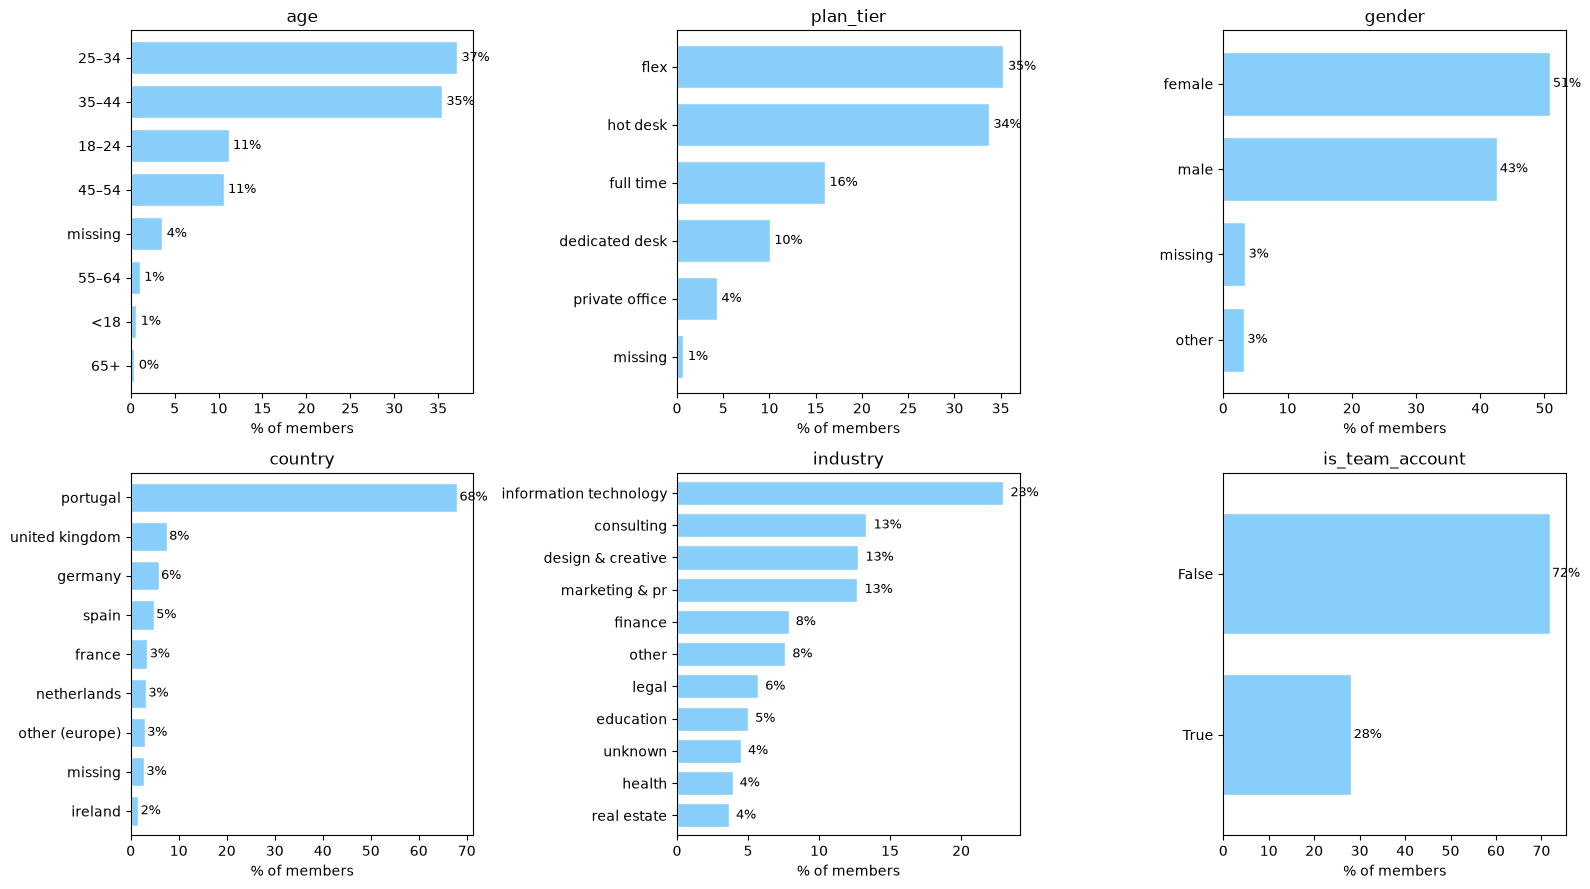

In [37]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9), tight_layout=True)
categories = ['age', 'plan_tier', 'gender', 'country', 'industry', 'is_team_account']
for ax, col in zip(axes.flat, categories):
    if col == 'age':
        age_bins = [0, 18, 25, 35, 45, 55, 65, np.inf]
        age_labels = ['<18', '18–24', '25–34', '35–44', '45–54', '55–64', '65+']
        age_groups = pd.cut(acdc_dataset['age'], bins=age_bins, labels=age_labels, right=False)
        valcount = age_groups.value_counts(normalize=True, dropna=False, sort=False).mul(100)
    else:
        valcount = acdc_dataset[col].value_counts(normalize=True, dropna=False).mul(100)
    valcount.index = ['missing' if pd.isna(x) else str(x) for x in valcount.index]
    valcount.sort_values().plot.barh(ax=ax, color=Graph_Color[1], edgecolor=Edgecolor[1], width=0.75)
    ax.set_title(col)
    ax.set_xlabel('% of members')
    for p in ax.patches:
        ax.text(p.get_width() + 0.5, p.get_y() + p.get_height() / 2, f'{p.get_width():.0f}%', va='center', fontsize=9, color='black')

plt.show()

- age group follows a normal distribution, however there are a few outliers with impossible and missing values which should be addressed in the next steps.
- almost 70% of plans are betweenthe cheapest options of flex and hot desk, which makes sense, since most user accounts are held by individuals.
- most users are from Portugal and work in IT, consulting, marketing or similar jobs which require office usage.
- regarding gender distribution we observe a slight majority towards female but not by much being amost equally distributed.

## Member activity

C:\Users\tiago\AppData\Local\Temp\ipykernel_2264\3382208055.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(acdc_dataset['avg_weekly_visits'].dropna(), vert=False, widths=0.6)


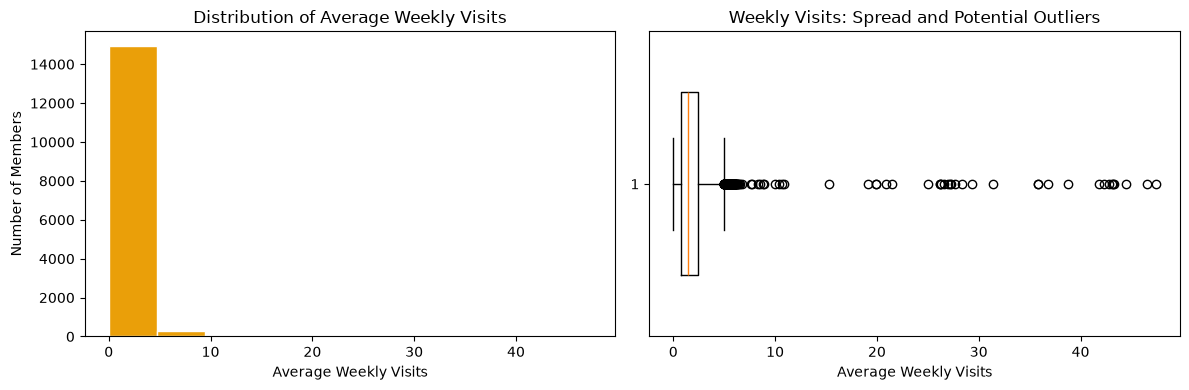

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), tight_layout=True)

axes[0].hist(acdc_dataset['avg_weekly_visits'].dropna(), bins=10, edgecolor=Edgecolor[1], color= Graph_Color[0])
axes[0].set_title('Distribution of Average Weekly Visits')
axes[0].set_xlabel('Average Weekly Visits')
axes[0].set_ylabel('Number of Members')

axes[1].boxplot(acdc_dataset['avg_weekly_visits'].dropna(), vert=False, widths=0.6)
axes[1].set_title('Weekly Visits: Spread and Potential Outliers')
axes[1].set_xlabel('Average Weekly Visits')

plt.show()

Average weekly visits captures the regular intensity of workspace use and is more comparable across members than total visits alone, since memberships may have different durations. 
- The graphs show that most users have a number of visits between 0 and 5 as expect, most users probably use the service at most once a day.
- The boxplot reveals that there are some outliers who use the service a lot more than would be expected. Perhaps the user is being used by several diferent people

## Lifetime value

C:\Users\tiago\AppData\Local\Temp\ipykernel_2264\1748525664.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


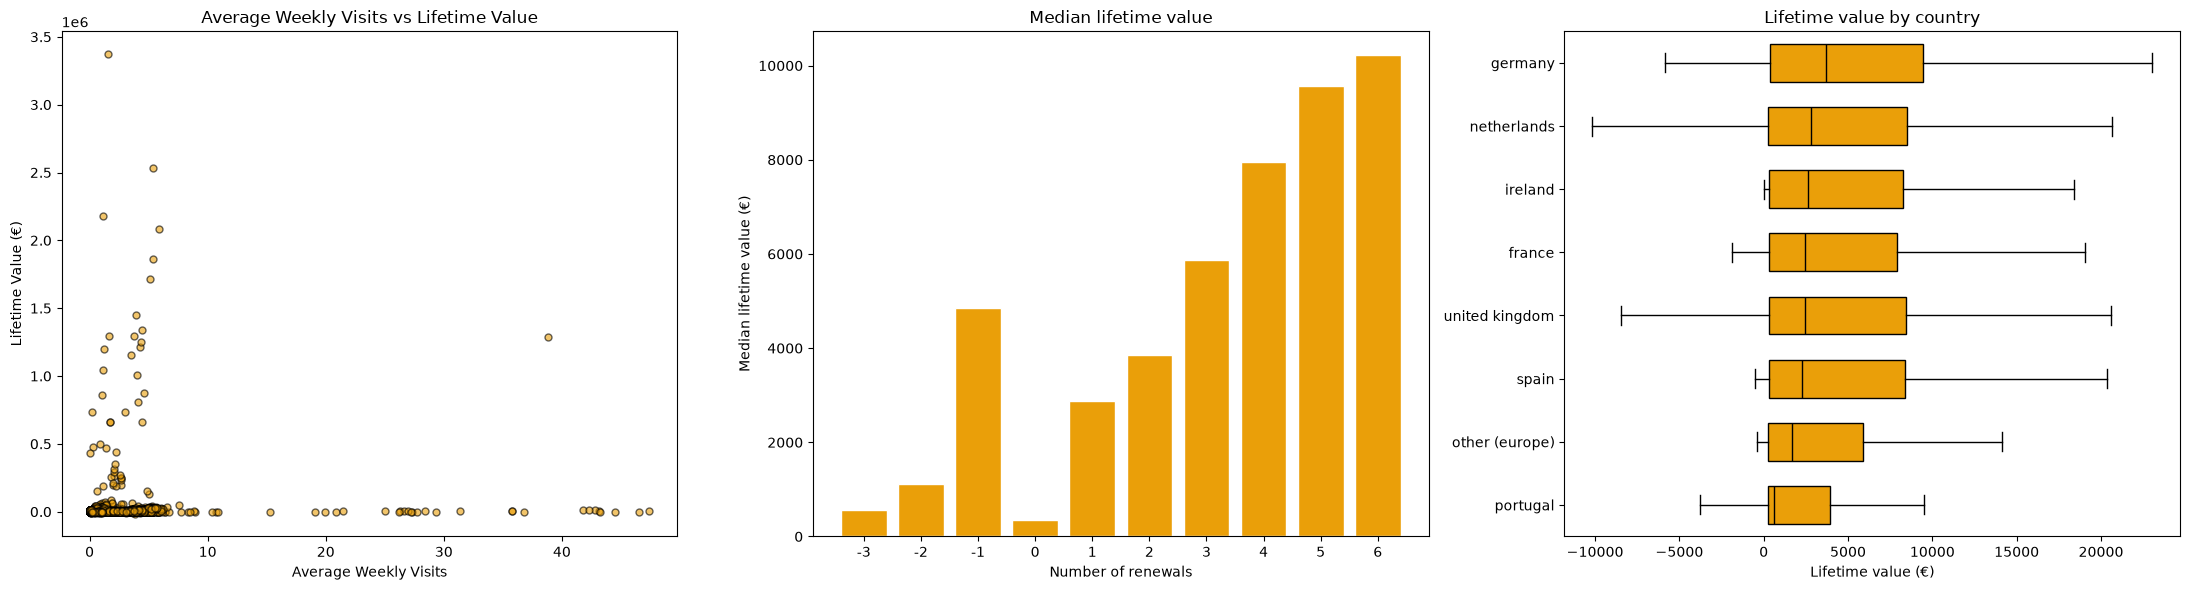

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))


ax = axes[0]
value_activity = acdc_dataset[['avg_weekly_visits', 'lifetime_value']].dropna()
ax.scatter(
    value_activity['avg_weekly_visits'],
    value_activity['lifetime_value'],
    alpha=0.6,
    color=Graph_Color[0],
    edgecolors=Edgecolor[0],
    s=25
)
ax.set_title('Average Weekly Visits vs Lifetime Value')
ax.set_xlabel('Average Weekly Visits')
ax.set_ylabel('Lifetime Value (€)')


ax = axes[1]
med = acdc_dataset.groupby('n_renewals')['lifetime_value'].median()
ax.bar(
    med.index.astype(int).astype(str), 
    med.values, color=Graph_Color[0], 
    edgecolor=Edgecolor[1]
)
ax.set_xlabel('Number of renewals')
ax.set_ylabel('Median lifetime value (€)')
ax.set_title('Median lifetime value')


ax = axes[2]
order = acdc_dataset.groupby('country')['lifetime_value'].median().sort_values().index
data = [acdc_dataset.loc[acdc_dataset['country'] == c, 'lifetime_value'].dropna() for c in order]
ax.boxplot(
    data, 
    vert=False, 
    showfliers=False, 
    patch_artist=True, 
    widths=0.6,
    boxprops=dict(facecolor=Graph_Color[0]), 
    medianprops=dict(color='black')
)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xlabel('Lifetime value (€)')
ax.set_title('Lifetime value by country')

plt.tight_layout()
plt.show()

### Lifetime value per plan tier

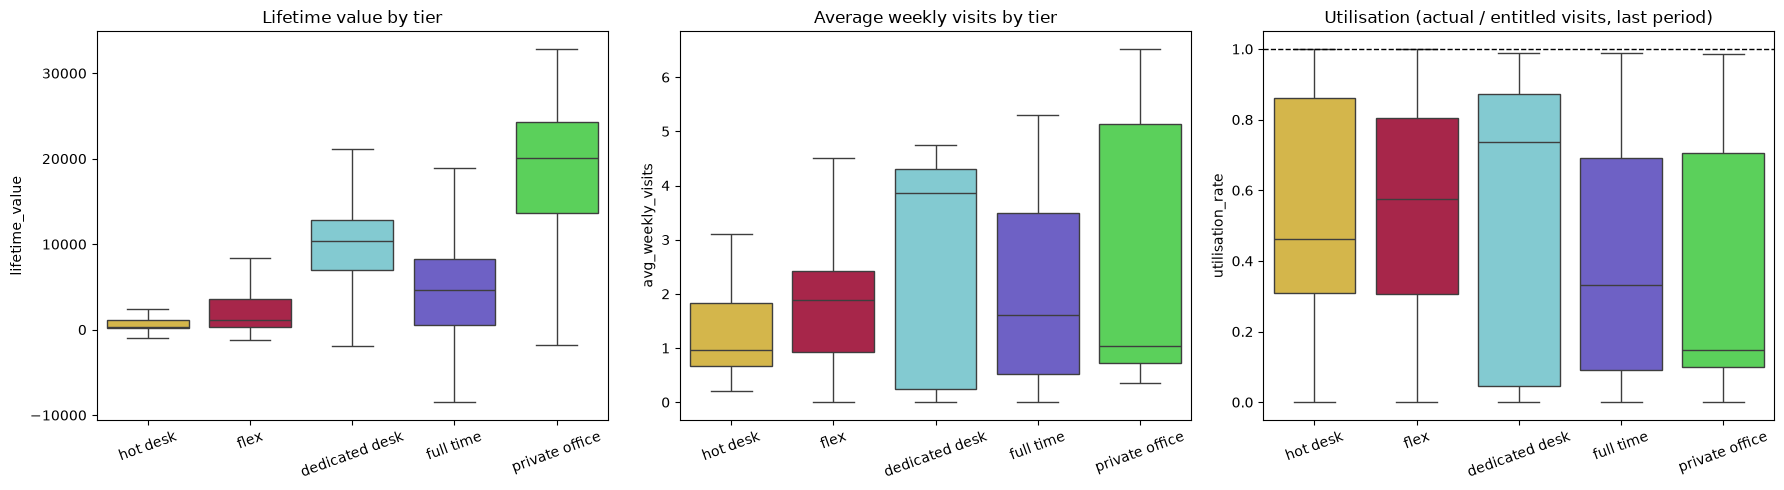

,members,median_ltv,median_weekly_visits,median_utilisation
plan_tier,,,,
hot desk,5153,317.94,0.96,0.462479
flex,5394,1161.29,1.89,0.574933
dedicated desk,1532,10366.80,3.86,0.735971
full time,2444,4621.97,1.61,0.333000
private office,657,20024.19,1.04,0.147856


In [40]:
acdc_dataset['visit_utilization_rate'] = np.where(
    acdc_dataset['entitled_visits_last_period'] > 0,
    acdc_dataset['actual_visits_last_period'] / acdc_dataset['entitled_visits_last_period'],
    np.nan
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=acdc_dataset, x='plan_tier', y='lifetime_value', hue='plan_tier', legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[0], showfliers=False)
axes[0].set_title('Lifetime value by tier')
sns.boxplot(data=acdc_dataset, x='plan_tier', y='avg_weekly_visits', hue='plan_tier', legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[1], showfliers=False)
axes[1].set_title('Average weekly visits by tier')
sns.boxplot(x=acdc_dataset.plan_tier, y=acdc_dataset.visit_utilization_rate, hue=acdc_dataset.plan_tier, legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[2], showfliers=False)
axes[2].axhline(1, color=Edgecolor[0], ls='--', lw=1)
axes[2].set_title('Utilisation (actual / entitled visits, last period)')
axes[2].set_ylabel('utilisation_rate')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

acdc_dataset.groupby('plan_tier', observed=True).agg(
    members=('member_id', 'size'),
    median_ltv=('lifetime_value', 'median'),
    median_weekly_visits=('avg_weekly_visits', 'median'),
    median_utilisation=('visit_utilization_rate', 'median'),
).reindex(Tier_Order)

## Plan utilization

Recent plan utilization (`visit_utilization_rate`) compares the number of visits a member actually made with the number included in their plan during the last period. A value of 1 means the member used their full entitlement, and lower values mean unused capacity. Members with zero entitlement are left undefined to avoid creating an artificial ratio.

The average utilization rate is about 0.52, and the middle 50% of members range from about 0.24 to 0.80. Members vary a lot in how fully they use the access they buy.

In [41]:
acdc_dataset[['entitled_visits_last_period', 'actual_visits_last_period', 'visit_utilization_rate']].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
entitled_visits_last_period,15283.0,27.51,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15283.0,13.79,11.39,0.0,5.00,10.00,20.00,60.00
visit_utilization_rate,15273.0,0.52,0.31,0.0,0.24,0.52,0.80,1.00


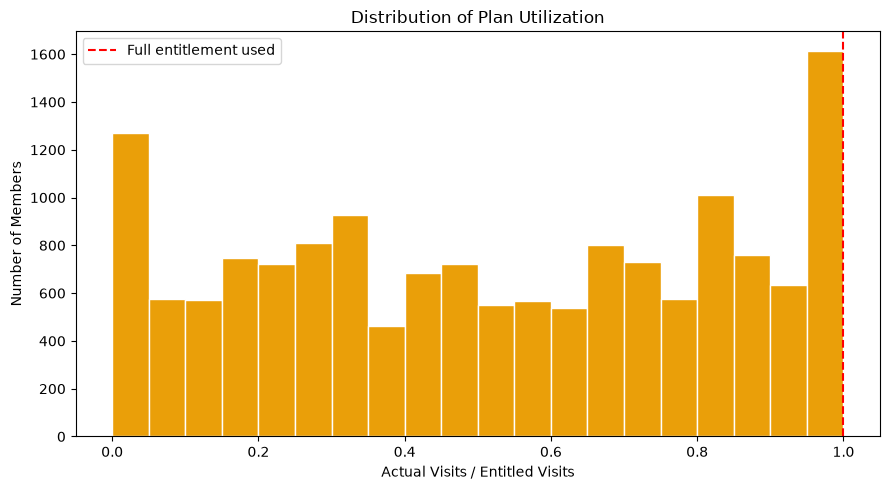

In [42]:
plt.figure(figsize=(9, 5))
plt.hist(acdc_dataset['visit_utilization_rate'].dropna(), bins=20, edgecolor=Edgecolor[1], color=Graph_Color[0])
plt.axvline(1, linestyle='--', color='red', linewidth=1.5, label='Full entitlement used')
plt.title('Distribution of Plan Utilization')
plt.xlabel('Actual Visits / Entitled Visits')
plt.ylabel('Number of Members')
plt.legend()
plt.tight_layout()
plt.show()

- Most members pay for more visits than they use: about half used less than 50% of their entitlement in the last period, and only about 15% used 90% or more.

In [43]:
acdc_dataset.groupby('is_active')['visit_utilization_rate'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11364.0,0.57,0.28,0.0,0.31,0.57,0.81,1.0
True,3909.0,0.38,0.36,0.0,0.05,0.23,0.74,1.0


- Active members show much lower recent utilization than churned members. For active members the last period is still in progress at the extraction date, so their visits are incomplete. This variable is therefore biased by membership status, and the Feature Engineering section replaces it with a utilization measure that covers the whole membership (`lifetime_utilization`).

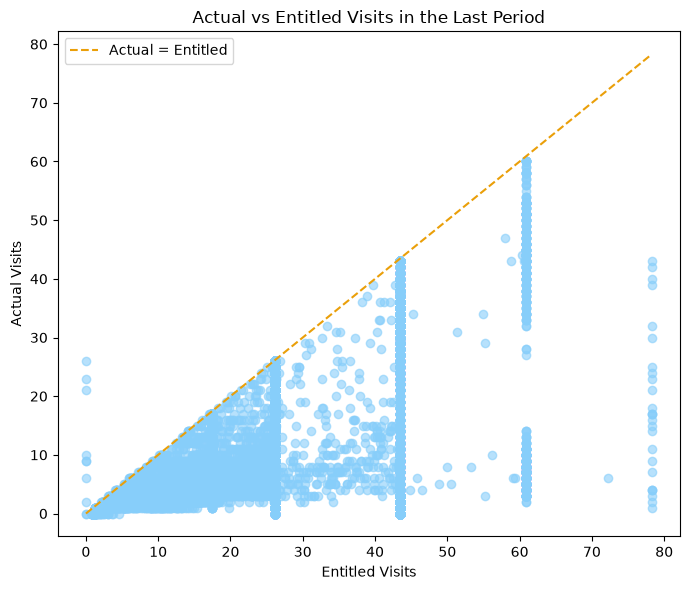

In [44]:
visit_comparison = acdc_dataset[['entitled_visits_last_period', 'actual_visits_last_period']].dropna()

plt.figure(figsize=(7, 6))
plt.scatter(
    visit_comparison['entitled_visits_last_period'],
    visit_comparison['actual_visits_last_period'],
    alpha=0.6,
    color=Graph_Color[1]
)

max_value = visit_comparison.max().max()
plt.plot([0, max_value], [0, max_value], linestyle='--', color=Graph_Color[0], label='Actual = Entitled')
plt.title('Actual vs Entitled Visits in the Last Period')
plt.xlabel('Entitled Visits')
plt.ylabel('Actual Visits')
plt.legend()
plt.tight_layout()
plt.show()

## Use of additional services

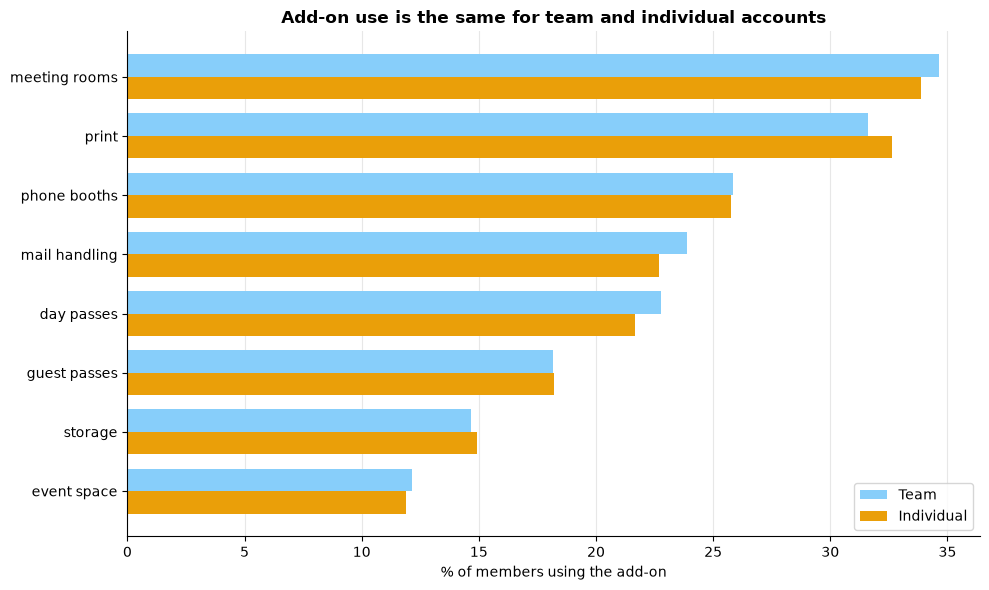

In [45]:
addons = ['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print',
          'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage']

adoption = (acdc_dataset.groupby('is_team_account')[addons].mean().mul(100).T
            .rename(columns={False: 'Individual', True: 'Team'}))
adoption.index = [a.replace('uses_', '').replace('_', ' ') for a in adoption.index]
adoption = adoption.sort_values('Individual')

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(adoption))
h = 0.38
ax.barh(y + h/2, adoption['Team'], height=h, color=Graph_Color[1], label='Team')
ax.barh(y - h/2, adoption['Individual'], height=h, color=Graph_Color[0], label='Individual')
ax.set_yticks(y)
ax.set_yticklabels(adoption.index)
ax.set_xlabel('% of members using the add-on')
ax.set_title('Add-on use is the same for team and individual accounts', fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

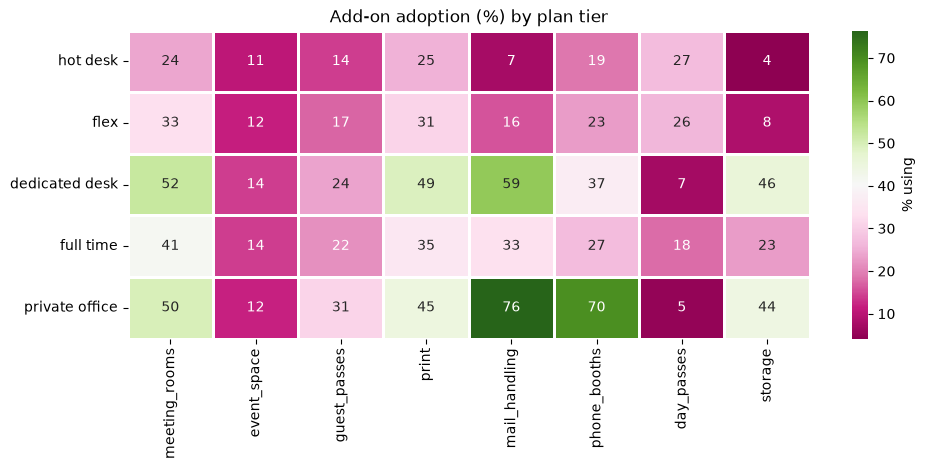

In [48]:
heat = acdc_dataset.groupby('plan_tier', observed=True)[addons].mean().mul(100).reindex(Tier_Order)
heat.columns = [c.replace('uses_', '') for c in heat.columns]
plt.figure(figsize=(11, 4))
sns.heatmap(heat, annot=True, fmt='.0f', cmap=Heatmap[0], cbar_kws={'label': '% using'}, linewidths=2, linecolor=Edgecolor[1])
plt.title('Add-on adoption (%) by plan tier')
plt.ylabel('')
plt.show()

## Team accounts versus individual accounts

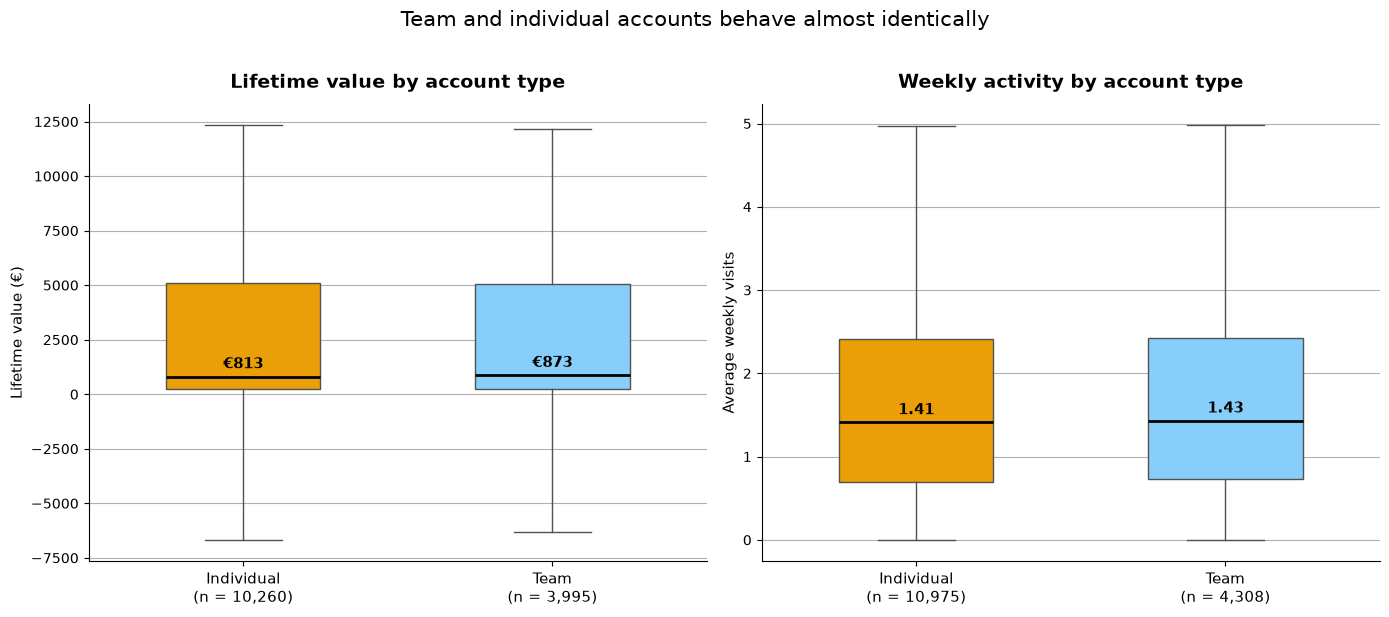

In [49]:
team_labels = {False: 'Individual', True: 'Team'}
comparison_df = acdc_dataset[['lifetime_value', 'avg_weekly_visits']].copy()
comparison_df['account_type'] = acdc_dataset['is_team_account'].map(team_labels)

labels = ['Individual', 'Team']
colors = [Graph_Color[0], Graph_Color[1]]
metrics = [
    ('lifetime_value', 'Lifetime value by account type', 'Lifetime value (€)', '€{:,.0f}'),
    ('avg_weekly_visits', 'Weekly activity by account type', 'Average weekly visits', '{:.2f}'),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (col, title, ylabel, fmt) in zip(axes, metrics):
    groups = [comparison_df.loc[comparison_df['account_type'] == l, col].dropna() for l in labels]

    bp = ax.boxplot(groups, patch_artist=True, showfliers=False, widths=0.5,
                    medianprops=dict(color='black', linewidth=2),
                    whiskerprops=dict(color='#52514e'), capprops=dict(color='#52514e'))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor('#52514e')

    for i, g in enumerate(groups, start=1):
        ax.annotate(fmt.format(g.median()), xy=(i, g.median()), xytext=(0, 6),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')

    ax.set_xticks([1, 2])
    ax.set_xticklabels([f'{l}\n(n = {len(g):,})' for l, g in zip(labels, groups)], fontsize=11)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(axis='y')
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

fig.suptitle('Team and individual accounts behave almost identically', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

- observing both graphs shows that both team and individuals have aproximatly the same lifetime value and the sames average visits per week.

# Age, industry and is_team_account per plan


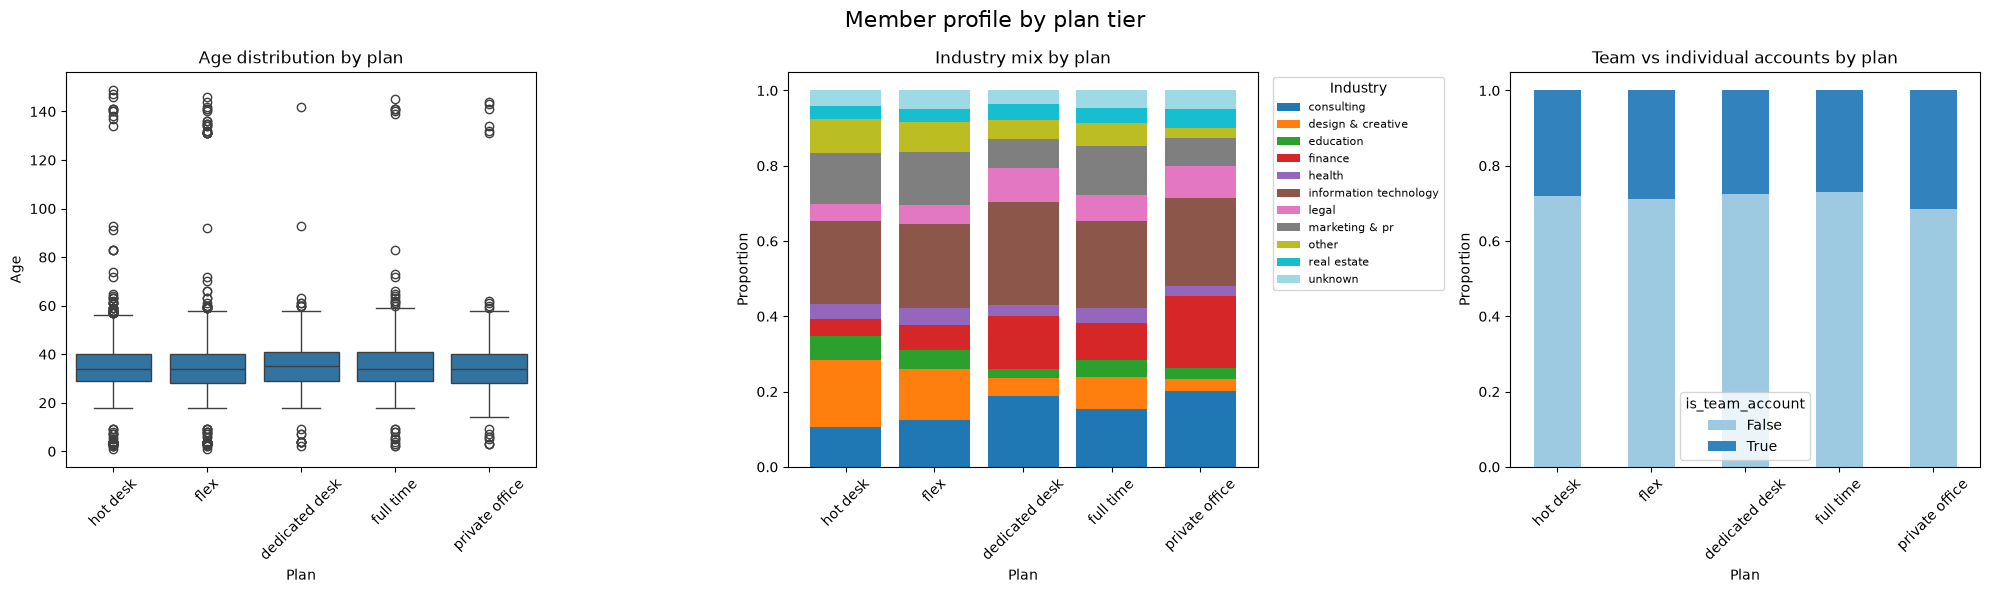

In [52]:
plan_col = "plan_tier"

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1) Age by plan
sns.boxplot(data=acdc_dataset, x=plan_col, y="age", order=Tier_Order, ax=axes[0])
axes[0].set_title("Age distribution by plan")
axes[0].set_xlabel("Plan"); axes[0].set_ylabel("Age")
axes[0].tick_params(axis="x", rotation=45)

# 2) Industry by plan (proportion within each plan)
ind_ct = pd.crosstab(acdc_dataset[plan_col], acdc_dataset["industry"], normalize="index").reindex(Tier_Order)
ind_ct.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab20", width=0.8)
axes[1].set_title("Industry mix by plan")
axes[1].set_xlabel("Plan"); axes[1].set_ylabel("Proportion")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="Industry", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

# 3) Team account by plan (proportion within each plan)
team_ct = pd.crosstab(acdc_dataset[plan_col], acdc_dataset["is_team_account"], normalize="index").reindex(Tier_Order)
team_ct.plot(kind="bar", stacked=True, ax=axes[2], color=["#9ecae1", "#3182bd"])
axes[2].set_title("Team vs individual accounts by plan")
axes[2].set_xlabel("Plan"); axes[2].set_ylabel("Proportion")
axes[2].tick_params(axis="x", rotation=45)
axes[2].legend(title="is_team_account", labels=["False", "True"])

plt.suptitle("Member profile by plan tier", fontsize=16)
plt.tight_layout()
plt.show()

**Age by plan:** Age is nearly identical across all plans(median~34), so it doesnt appear to seperate plan types.  
**Industry by plan:** IT dominates every plan, with only mild shifts (more Consulting and Finance in higher commitment plans, more Design and Creative in flexible ones).  
**Team vs individual by plan:** About 28% of members are on team accounts in every plan, so team status is independent of plan.

## Correlation between numerical segmentation variables

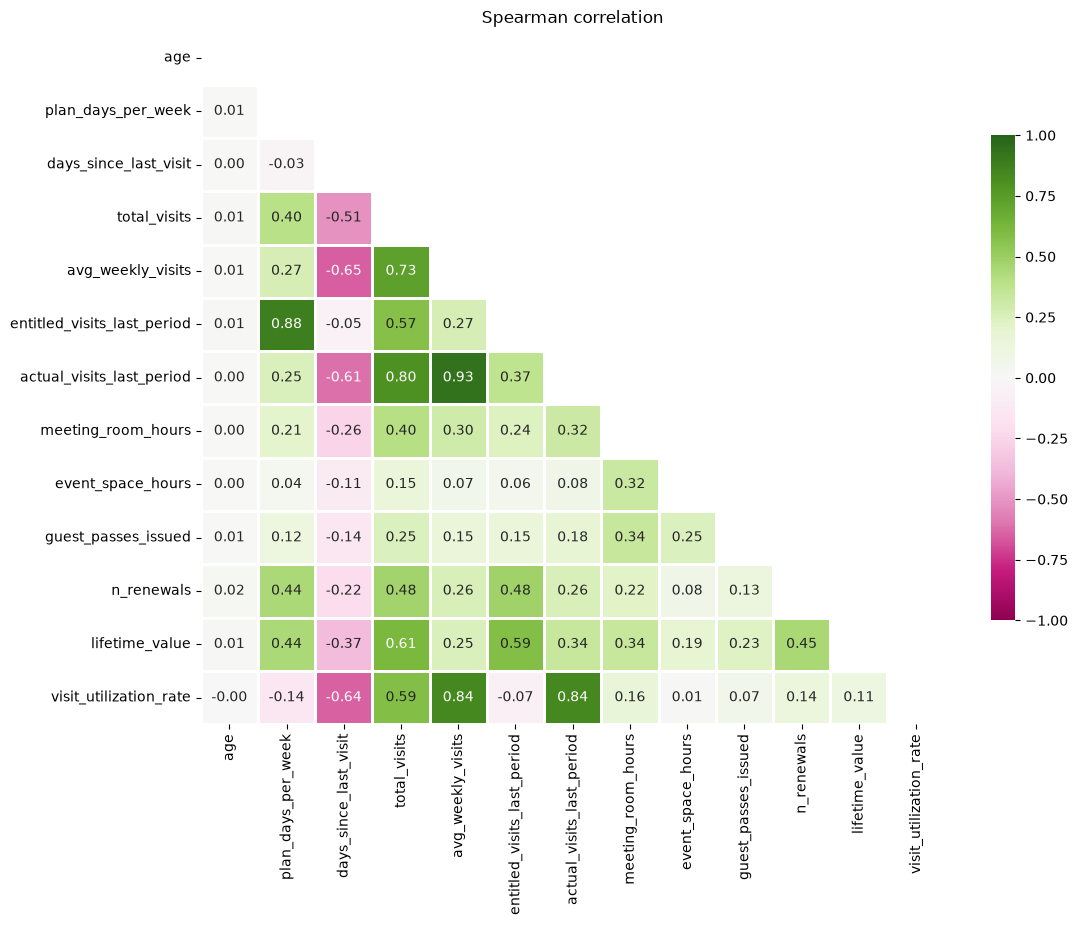

In [50]:
corr_cols =  [
    'age', 'plan_days_per_week', 'days_since_last_visit', 'total_visits',
    'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period',
    'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
    'n_renewals', 'lifetime_value', 'visit_utilization_rate'
]
corr = acdc_dataset[corr_cols].corr(method='spearman')
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap=Heatmap[0], center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor='white', cbar_kws={'shrink': .7})
plt.title('Spearman correlation')
plt.show()

- We can observe that most feature relating to visit count have a strong correlation, as would be expected. Perhaps some of these features may be redundant and could be eleiminated in next steps.
- ltv has, as expected, some positive correlation with visit count features, and we can also see that it has a negative correlation with the more days pass since last visit.
- Age does not seem to have any correlation with any of the other numeric features.

# Feature Engineering

### Recency_vs_usal_gap

In [53]:
# Limpar os inputs (sem alterar as colunas originais)
weekly = acdc_dataset['avg_weekly_visits'].replace(0, np.nan)                                    # 0 -> NaN (evita divisão por zero)

# Intervalo habitual entre visitas (em dias)
usual_gap_days = 7 / weekly

# Feature: dias desde a última visita / intervalo habitual
acdc_dataset['recency_vs_usual_gap'] =  acdc_dataset['days_since_last_visit']/ usual_gap_days

# Verificação rápida
print(acdc_dataset['recency_vs_usual_gap'].describe())
print("NaN:", acdc_dataset['recency_vs_usual_gap'].isna().sum())

count    15269.000000
mean        19.307647
std         75.645794
min       -550.500000
25%          1.097143
50%          2.488571
75%          5.622857
max       2982.728571
Name: recency_vs_usual_gap, dtype: float64
NaN: 14


`recency_vs_usual_gap` measures how overdue a member is for their next visit, relative to their own typical rhythm. It divides the days since their last visit by their usual gap between visits (7 / average weekly visits).

- ≈ 1: on schedule, behaving as usual.
- \> 1: overdue. A value of 5 means they have missed about five expected visits, which can signal disengagement or churn risk.
- < 1: visited recently, within their normal gap.

### Usage_rate_last_period

In [54]:
# Entitled = 0 -> NaN (avoids division by zero)
entitled = acdc_dataset['entitled_visits_last_period'].replace(0, np.nan)

# Feature: share of the plan's entitled visits actually used
acdc_dataset['usage_rate_last_period'] = (
    acdc_dataset['actual_visits_last_period'] / entitled
)

# Quick check
print(acdc_dataset['usage_rate_last_period'].describe())
print("NaN:", acdc_dataset['usage_rate_last_period'].isna().sum())
print("Above 1:", (acdc_dataset['usage_rate_last_period'] > 1).sum())

count    15273.000000
mean         0.517258
std          0.312205
min          0.000000
25%          0.239425
50%          0.517539
75%          0.804906
max          1.000000
Name: usage_rate_last_period, dtype: float64
NaN: 10
Above 1: 0


`usage_rate_last_period` measures the share of their plan’s entitled visits a member actually used in the last period (actual visits / entitled visits), on a scale from 0 to 1.

- Near 0: “paying but absent”. They have the plan but rarely show up, which is a possible churn risk.
- Around 0.5: moderate use of the plan.
- Near 1: they use almost everything the plan includes.

### Usage_rate

In [55]:
# plan_days_per_week = 0 -> NaN (avoids division by zero)
plan_days = acdc_dataset['plan_days_per_week'].replace(0, np.nan)

# Feature: average weekly visits relative to the days the plan includes
acdc_dataset['usage_rate'] = acdc_dataset['avg_weekly_visits'] / plan_days

# Quick check
print(acdc_dataset['usage_rate'].describe())
print("NaN:", acdc_dataset['usage_rate'].isna().sum())
print("Above 1:", (acdc_dataset['usage_rate'] > 1).sum())

count    15240.000000
mean         0.545204
std          0.485258
min          0.000000
25%          0.253333
50%          0.515000
75%          0.823333
max          9.950000
Name: usage_rate, dtype: float64
NaN: 43
Above 1: 50


`usage_rate` measures how much of their plan’s weekly days a member typically uses, based on their long-run average (average weekly visits / plan days per week).

- Near 0: the member pays for days they almost never use, a sign of low commitment and possible churn risk.
- Around 0.5: they use about half of the days their plan includes.
- Near 1: they attend as often as the plan allows, a fully committed, “get what you pay for” user.

### Visit_trend

In [56]:
# Weeks in the last period, inferred per member
plan_days = acdc_dataset['plan_days_per_week'].replace(0, np.nan)
weeks_in_period = acdc_dataset['entitled_visits_last_period'] / plan_days

# Visits we would expect in that period, given the member's historical average
expected_visits = (acdc_dataset['avg_weekly_visits'] * weeks_in_period).replace(0, np.nan)

# Feature: recent visits vs. historical pace
acdc_dataset['visit_trend'] = acdc_dataset['actual_visits_last_period'] / expected_visits

# Quick check
print(acdc_dataset['visit_trend'].describe())
print("NaN:", acdc_dataset['visit_trend'].isna().sum())

count    15227.000000
mean         0.979120
std          0.241356
min          0.000000
25%          0.884580
50%          0.991340
75%          1.089274
max          5.732484
Name: visit_trend, dtype: float64
NaN: 56


`visit_trend` compares a member’s visits in the last period with what their own historical average predicts.

- Below 1: fading, with fewer visits than usual. This is an early churn-risk signal, and values around 0.7 or lower are the clearest warnings.
- Around 1: stable, behaving as they always have.
- Above 1: ramping up, with more visits than usual.

### Value_per_month

In [57]:
# Tenure in months (active members end at the snapshot date)
snapshot = pd.Timestamp('2023-12-31')
end = acdc_dataset['membership_end'].fillna(snapshot)      # NaT = still active
tenure_months = (end - acdc_dataset['membership_start']).dt.days / 30.44

# Feature
acdc_dataset['value_per_month'] = acdc_dataset['lifetime_value'] / tenure_months

# Quick check
print(acdc_dataset['value_per_month'].describe())
print("NaN:", acdc_dataset['value_per_month'].isna().sum())

count     14255.000000
mean        353.577987
std        3596.915781
min     -139932.680000
25%         128.110807
50%         190.448522
75%         306.881333
max      166811.200000
Name: value_per_month, dtype: float64
NaN: 1028


`value_per_month` is the average monthly revenue a member generates (lifetime value / months of membership).

- Low values: members on cheap plans or with little paid usage, such as hot desk or flex users.
- Medium values: the typical paying member, around €190 per month.
- High values: premium members, such as private office or dedicated desk plans, or heavy buyers of extra services like meeting rooms.

# EDA with the new features

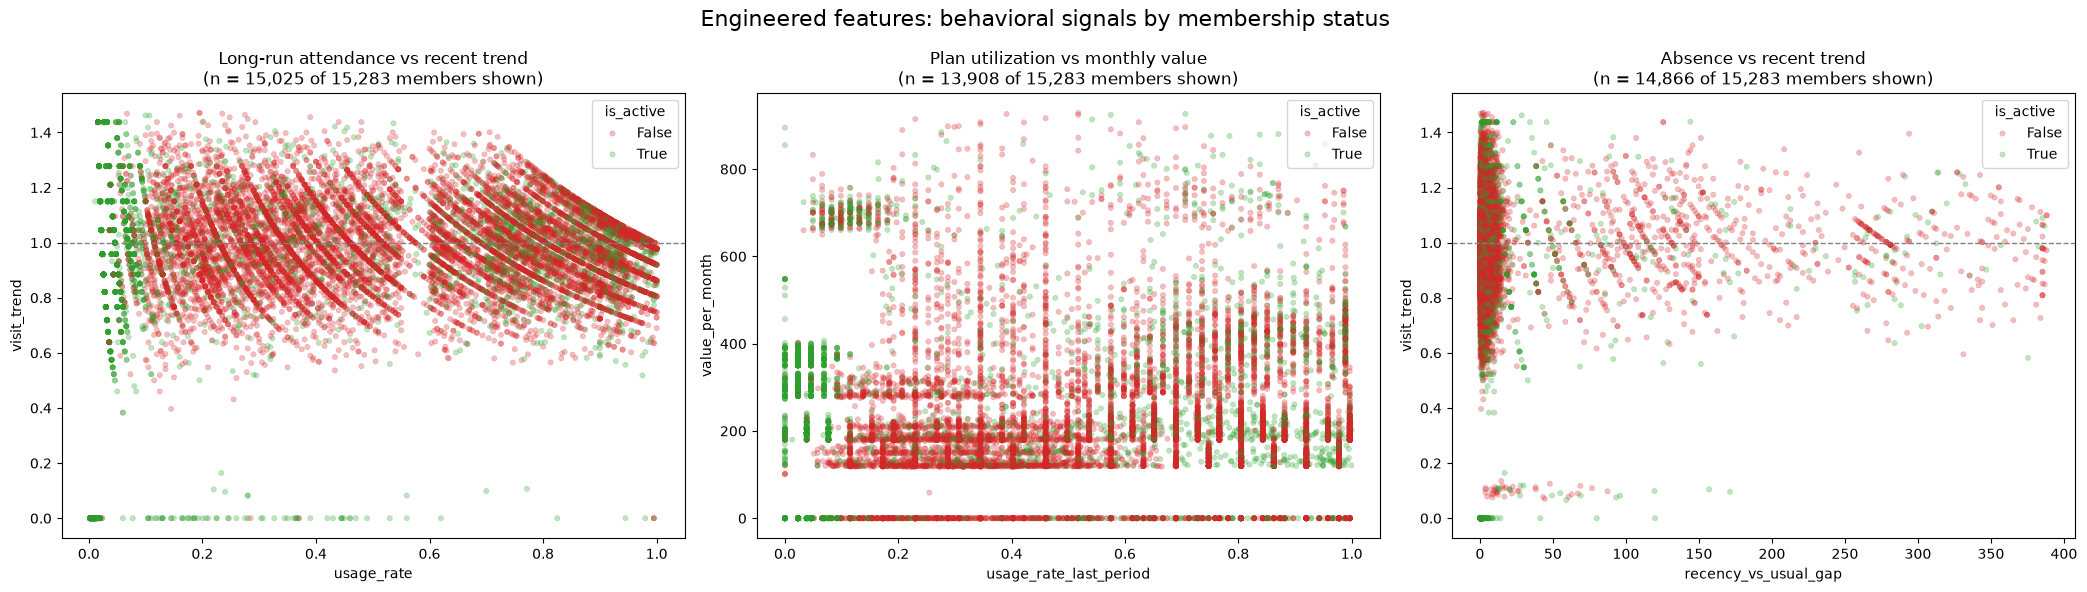

In [60]:
# Column names
ATT   = "usage_rate"
TREND = "visit_trend"
UTIL  = "usage_rate_last_period"
VALUE = "value_per_month"
GAP   = "recency_vs_usual_gap"

df = acdc_dataset

# Plot-only filters
def q99(s):
    return s.quantile(0.99)

# Plot 1: attendance vs trend
p1 = df[[ATT, TREND, "is_active"]].dropna()
p1 = p1[p1[ATT].between(0, 1) & p1[TREND].between(0, q99(p1[TREND]))]

# Plot 2: utilization vs value
p2 = df[[UTIL, VALUE, "is_active"]].dropna()
p2 = p2[p2[UTIL].between(0, 1) & p2[VALUE].between(0, q99(p2[VALUE]))]

# Plot 3: absence vs trend
p3 = df[[GAP, TREND, "is_active"]].dropna()
p3 = p3[p3[GAP].between(0, q99(p3[GAP])) & p3[TREND].between(0, q99(p3[TREND]))]

# ---- Figure ----
palette = {True: "#2ca02c", False: "#d62728"}   # green = active, red = churned

plots = [
    (p1, ATT, TREND, "Long-run attendance vs recent trend"),
    (p2, UTIL, VALUE, "Plan utilization vs monthly value"),
    (p3, GAP, TREND, "Absence vs recent trend"),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for ax, (data, x, y, title) in zip(axes, plots):
    sns.scatterplot(data=data, x=x, y=y, hue="is_active", palette=palette,
                    alpha=0.3, s=15, edgecolor=None, ax=ax)
    ax.set_title(f"{title}\n(n = {len(data):,} of {len(df):,} members shown)")
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.legend(title="is_active", loc="best")

# Reference line for "stable" trend in the plots that use visit_trend
axes[0].axhline(1, color="gray", linestyle="--", linewidth=1)
axes[2].axhline(1, color="gray", linestyle="--", linewidth=1)

plt.suptitle("Engineered features: behavioral signals by membership status", fontsize=16)
plt.tight_layout()
plt.show()

**Attendance vs trend:** Most members are stable (trend ≈ 1) at every attendance level, and the two features are independent, with a distinct line of members who stopped visiting entirely (trend = 0).

**Utilization vs value:** Monthly value falls into fixed bands set by plan price and is unrelated to utilization, which reveals a group of high-paying members who rarely use their plan.

**Absence vs trend:** Active and churned members overlap heavily at every absence level, with churned members only modestly overrepresented in the long-absence tail, so recency is a weak separator of membership status.

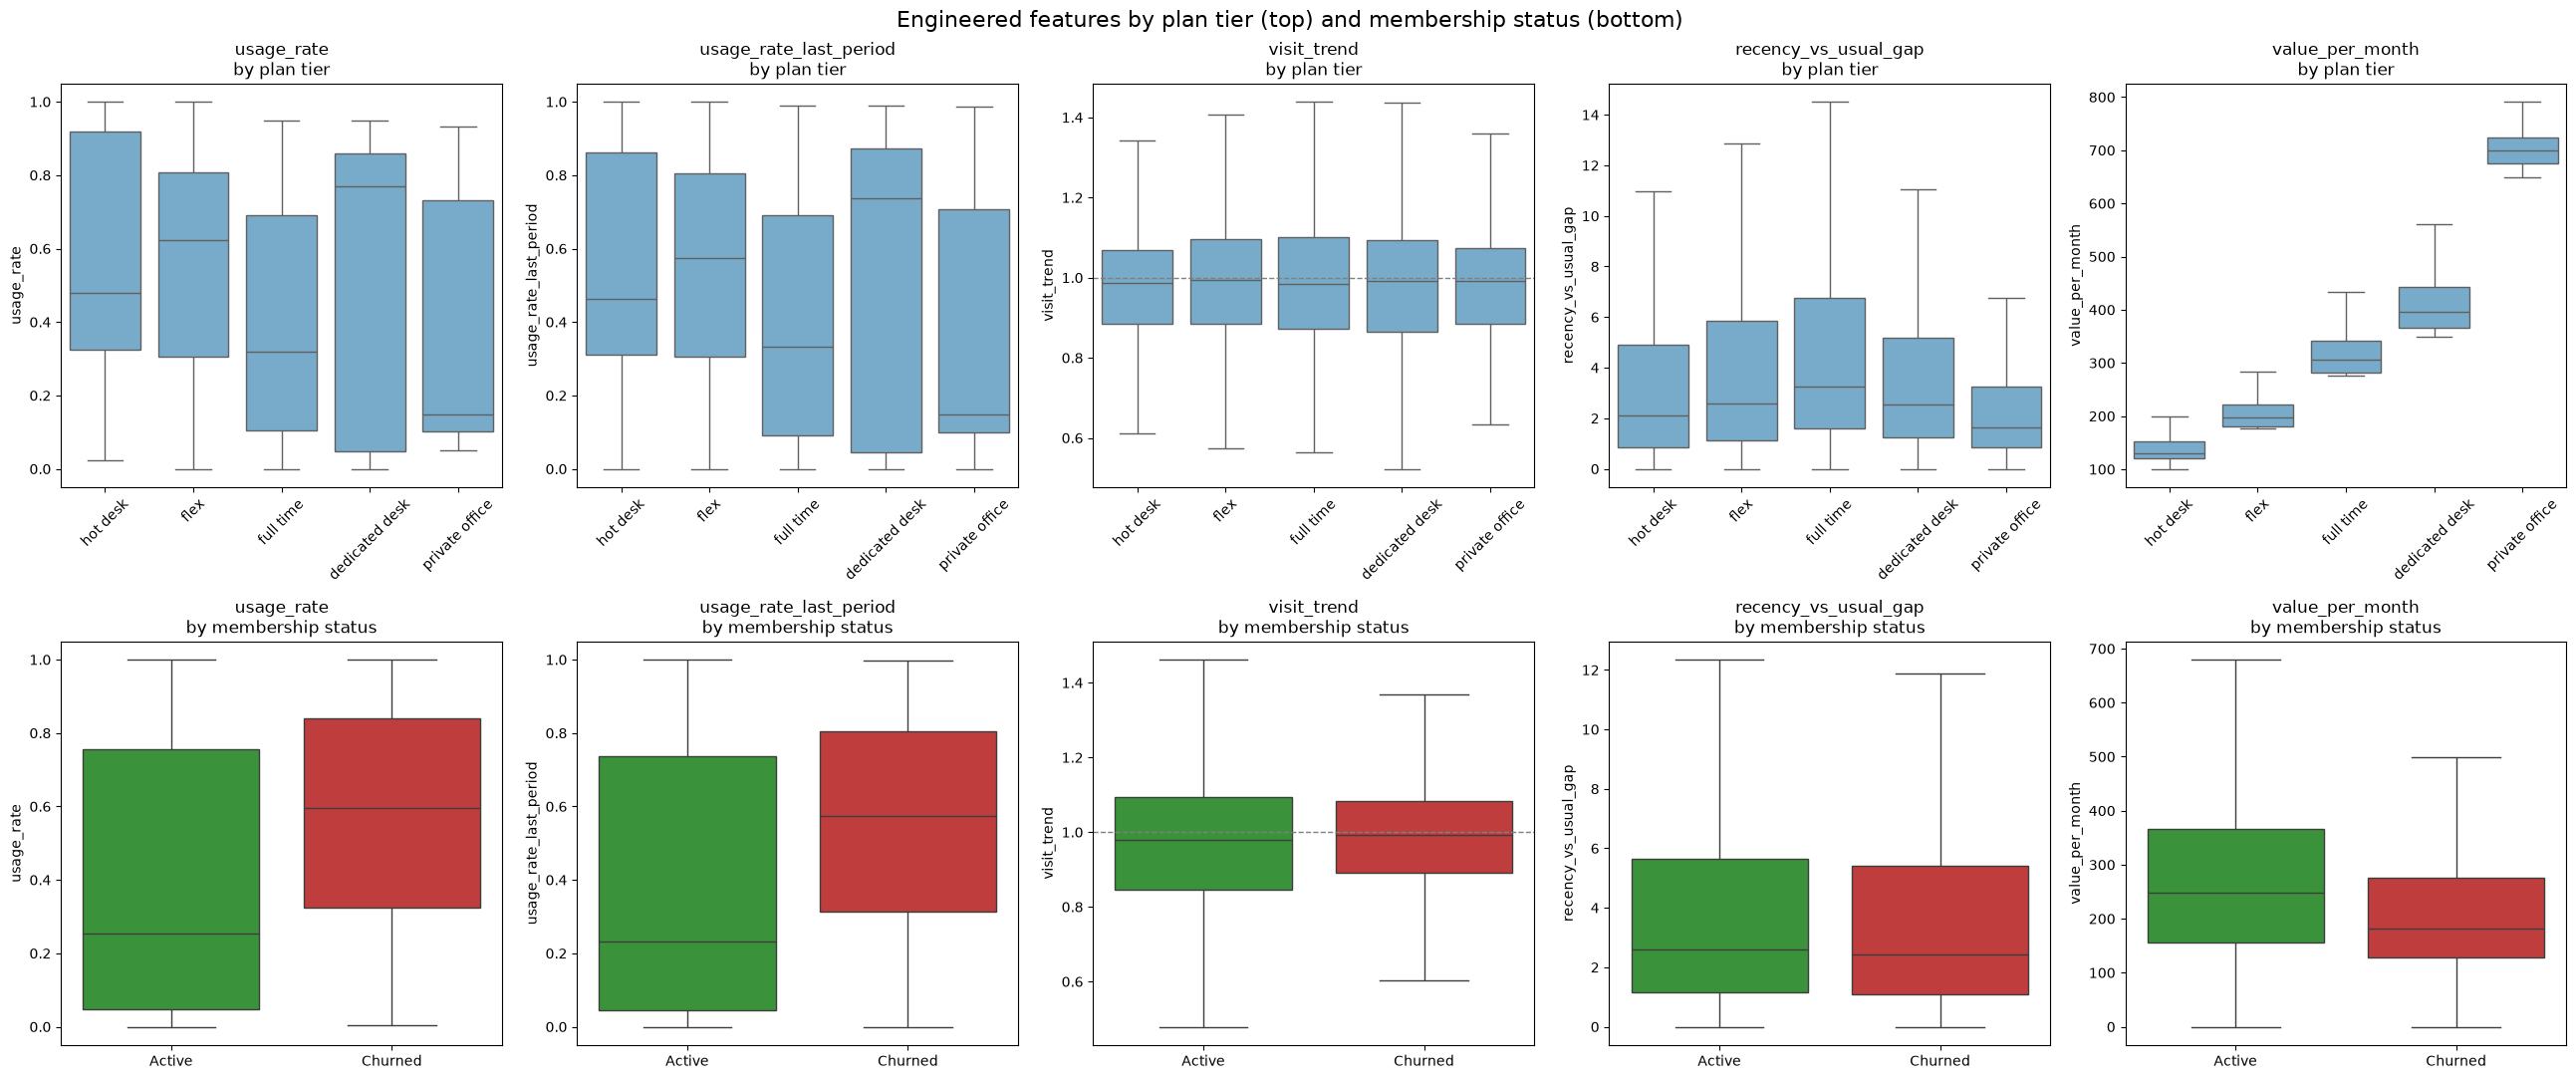

In [61]:
df = acdc_dataset                      # original data, never modified

plan_col = "plan_tier"
plan_order = ["hot desk", "flex", "full time", "dedicated desk", "private office"]  # adjust to your labels

# Feature -> (lower bound, upper bound) used ONLY for display. None = 99th percentile
features = {
    "usage_rate":                   (0, 1),
    "usage_rate_last_period":       (0, 1),
    "visit_trend":                  (0, None),
    "recency_vs_usual_gap":         (0, None),
    "value_per_month":              (0, None),
}

status_palette = {"Active": "#2ca02c", "Churned": "#d62728"}
df_plot_base = df.assign(status=df["is_active"].map({True: "Active", False: "Churned"}))

fig, axes = plt.subplots(2, len(features), figsize=(26, 11))

for j, (feat, (lo, hi)) in enumerate(features.items()):
    # Plot-only filter: drop NaN, impossible values and the top 1% extremes
    data = df_plot_base[[feat, plan_col, "status"]].dropna()
    upper = hi if hi is not None else data[feat].quantile(0.99)
    data = data[data[feat].between(lo, upper)]

    # Row 1: by plan tier
    sns.boxplot(data=data, x=plan_col, y=feat, order=plan_order,
                showfliers=False, color="#6baed6", ax=axes[0, j])
    axes[0, j].set_title(f"{feat}\nby plan tier")
    axes[0, j].set_xlabel("")
    axes[0, j].tick_params(axis="x", rotation=45)

    # Row 2: by membership status
    sns.boxplot(data=data, x="status", y=feat, order=["Active", "Churned"],
                palette=status_palette, hue="status", legend=False,
                showfliers=False, ax=axes[1, j])
    axes[1, j].set_title(f"{feat}\nby membership status")
    axes[1, j].set_xlabel("")

# Reference line for "stable" trend
for row in (0, 1):
    axes[row, 2].axhline(1, color="gray", linestyle="--", linewidth=1)

plt.suptitle("Engineered features by plan tier (top) and membership status (bottom)", fontsize=16)
plt.tight_layout()

- `value_per_month` follows plan tier. The median rises from about €130 (hot desk) to about €700 (private office) with little overlap, so it mostly reflects plan price. Active members also have a higher median (about €250) than churned members (about €180).
- Premium plans do not use their entitlements more. Private office members use the least (median about 0.15), while dedicated desk members use the most (about 0.75). This points to a “pays a lot but rarely comes” segment.
- Churned members show higher plan usage than active members (median about 0.6 versus about 0.25). This is the opposite of what we expected and needs further checking.
- `visit_trend` and `recency_vs_usual_gap` barely differ by plan or by status. Both are around 1 and 2.5 respectively in every group, so they are weak separators on their own.